# 03. Baseline Modelling: TF–IDF + Logistic Regression

**Project:** Text Analytics 2 — Analyzing Dating Problems and Advice on Reddit
**Role:** baseline modelling, i.e. a TF–IDF + logistic regression baseline with per-label precision, recall and F1.

The baseline sets the bar the transformer model has to beat, and it shows which parts of the task are hard. It covers two tasks:

| Task | Input | Predict | Why |
| :--- | :--- | :--- | :--- |
| **A. Advice type** | a top-level comment | 8 advice labels | The core baseline task from the team plan |
| **B. Post topic** | post title + text | 11 topic labels | The research question compares advice between situations, and the transformer model also classifies topics |

**Data:** 2,000 comments and 800 posts labelled by the AI annotator (`data/AI Annotations/`).

**Evaluation:** 5-fold cross-validation on folds shared with the transformer model, so both models are scored on exactly the same items.

**Contents:**
1. Setup
2. Data and labels
3. Method
4. Comments: advice type
5. Posts: topic
6. Export and summary

## 1. Setup
Libraries, settings and paths. `SEED = 42` makes every random step reproducible. The data is private and stays out of GitHub.

**Requirements:** Python 3.12 with `pandas`, `numpy`, `scikit-learn`, `matplotlib` and `openpyxl` (for reading the Excel files).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, PredefinedSplit, StratifiedGroupKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline

# A label that is never predicted gets F1 = 0; no need to warn every time.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

SEED = 42                  # makes every random step repeatable
N_FOLDS = 5
SHOW_TEXT_EXAMPLES = True  # set to False to hide Reddit text snippets from the outputs
SNIPPET_CHARS = 150        # how much of a text to show in examples

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Go up from the current folder until we find the project's data/ folder."""
    for folder in [start, *start.parents]:
        if (folder / "data" / "AI Annotations").is_dir():
            return folder
    raise FileNotFoundError("Could not find 'data/AI Annotations'. Run this notebook from inside the project folder.")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"
COMMENTS_FILE = DATA_DIR / "AI Annotations" / "AI_annotations_comments_active_5plus.xlsx"
POSTS_FILE = DATA_DIR / "AI Annotations" / "AI_annotated_posts_active_5plus.xlsx"
# The first-round files are only used to tell which items belong to the first labelling batch.
FIRST_ROUND_COMMENTS = DATA_DIR / "Final Annotations" / "final_annotations_comments_active_5plus.xlsx"
FIRST_ROUND_POSTS = DATA_DIR / "Final Annotations" / "unverified_posts_active_5plus.xlsx"
CLEAN_DIR = DATA_DIR / "data_clean"
OUT_DIR = DATA_DIR / "model_outputs"   # files for teammates (private, not for GitHub)
OUT_DIR.mkdir(exist_ok=True)


def read_clean(name: str) -> pd.DataFrame:
    """Read a clean file from notebook 01 (works with .csv or .csv.gz)."""
    for suffix in (".csv", ".csv.gz"):
        path = CLEAN_DIR / f"{name}{suffix}"
        if path.exists():
            return pd.read_csv(path, dtype={"submissionId": str, "parentPostId": str})
    raise FileNotFoundError(f"{name}.csv(.gz) not found in {CLEAN_DIR}")


# Chart style: blue for one series, blue + orange for two, light-to-dark blue for heatmaps
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
SEQ_BLUES = LinearSegmentedColormap.from_list("seq_blues", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
print(f"Project folder found: {ROOT.name}")

Project folder found: ta2_reddit_project


## 2. Data and labels

### 2.1 Loading
Comments and posts are read from the AI annotation files and checked against the clean dataset from notebook 01. The text is lightly cleaned:
- curly quotes become straight quotes, so *don’t* and *don't* are the same word;
- links become `URL`;
- whitespace is collapsed.

Posts are read as title + text; the title alone is kept for one comparison.

| Advice label (comments) | Meaning (annotation codebook) |
| :--- | :--- |
| Talk it through | Discuss and communicate with the person |
| Set boundary | Set and enforce a boundary |
| Repair/Help | Work through it together, apologise, see therapy |
| Wait/More info | Wait and see, or ask for more information |
| Leave/Disengage | Break up, block, ghost |
| Dating Strategy | Advice on getting a partner |
| Other | Clear advice that fits none of the above |
| No advice | Sarcastic, rude or otherwise unhelpful |

| Topic label (posts) | Meaning (annotation codebook) |
| :--- | :--- |
| Early Dating | Crushes and early-stage problems (under 6 months), including situationships |
| Breakups | How to break up, the aftermath, or seriously considering it |
| Reconciliation | Moving on from a conflict and fixing things |
| Communication | Problems mainly from poor communication or a communication mismatch |
| Conflict | Fights between people |
| Boundaries | Someone crossing personal boundaries |
| Trust | Not being able to trust what someone says or does |
| Cheating | Cheating |
| Uncertainty | Unsure about the future and how to move on |
| Sex/Intimacy | Sexual activity or other physical closeness |
| Other | Fits none of the above |

In [2]:
ADVICE_LABELS = ["Leave/Disengage", "Talk it through", "Set boundary", "Repair/Help",
                 "Wait/More info", "Dating Strategy", "Other", "No advice"]
TOPIC_LABELS = ["Early Dating", "Breakups", "Reconciliation", "Communication", "Conflict", "Boundaries",
                "Trust", "Cheating", "Uncertainty", "Sex/Intimacy", "Other"]


def read_annotations(path, id_cols):
    """Read an annotation spreadsheet; IDs are read as text."""
    df = pd.read_excel(path, dtype={col: str for col in id_cols})
    return df.drop(columns=[c for c in df.columns if c.startswith("Unnamed") or c == "index"])


def clean_label(series):
    """Remove stray spaces and unify spellings ('Break Ups' -> 'Breakups'). Empty cells stay empty."""
    cleaned = series.where(series.isna(), series.astype(str).str.strip())
    return cleaned.replace({"Break Ups": "Breakups"})


def prepare_text(text) -> str:
    text = str(text)
    text = text.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    return re.sub(r"\s+", " ", text).strip()


def snippet(text) -> str:
    """Shorten a text for display."""
    text = re.sub(r"\s+", " ", str(text)).strip()
    return text[:SNIPPET_CHARS] + ("…" if len(text) > SNIPPET_CHARS else "")


def load(path, first_round_path, id_cols, labels, clean_name):
    df = read_annotations(path, id_cols)
    df["label"] = clean_label(df["Primary Label"])
    df["label_secondary"] = clean_label(df["Secondary Label"])
    first_ids = set(read_annotations(first_round_path, id_cols)["submissionId"])
    df["batch"] = np.where(df["submissionId"].isin(first_ids), "first batch", "second batch")
    assert df["submissionId"].is_unique
    assert set(df["label"]) <= set(labels), set(df["label"]) - set(labels)
    clean = read_clean(clean_name)
    check = df[["submissionId", "bodyText"]].merge(clean[["submissionId", "bodyText"]], on="submissionId",
                                                   how="left", suffixes=("", "_clean"))
    assert (check["bodyText"] == check["bodyText_clean"]).all(), "Text differs from the clean dataset"
    return df


com = load(COMMENTS_FILE, FIRST_ROUND_COMMENTS, ["submissionId", "parentPostId"], ADVICE_LABELS, "comments_active_5plus")
com["thread"] = com["parentPostId"]          # comments under the same post form one thread
com["text"] = com["bodyText"].map(prepare_text)
com["n_words"] = com["bodyText"].astype(str).str.split().str.len()

post = load(POSTS_FILE, FIRST_ROUND_POSTS, ["submissionId"], TOPIC_LABELS, "posts_active_5plus")
post["thread"] = post["submissionId"]        # every post is its own thread
post["text"] = (post["title"].fillna("") + " . " + post["bodyText"].fillna("")).map(prepare_text)
post["title_text"] = post["title"].fillna("").map(prepare_text)
post["n_words"] = (post["title"].fillna("") + " " + post["bodyText"].fillna("")).str.split().str.len()

for what, df in [("Comments", com), ("Posts", post)]:
    batches = df["batch"].value_counts()
    print(f"{what}: {len(df):,} items from {df['thread'].nunique():,} threads "
          f"(first batch {batches['first batch']}, second batch {batches['second batch']}); text matches the clean dataset")

Comments: 2,000 items from 1,024 threads (first batch 500, second batch 1500); text matches the clean dataset
Posts: 800 items from 800 threads (first batch 200, second batch 600); text matches the clean dataset


### 2.2 Label counts

,items,share,median words
label,,,
Leave/Disengage,492,25%,62
Talk it through,122,6%,90
Set boundary,72,4%,84
Repair/Help,58,3%,98
Wait/More info,67,3%,47
Dating Strategy,110,6%,72
Other,60,3%,72
No advice,1019,51%,26


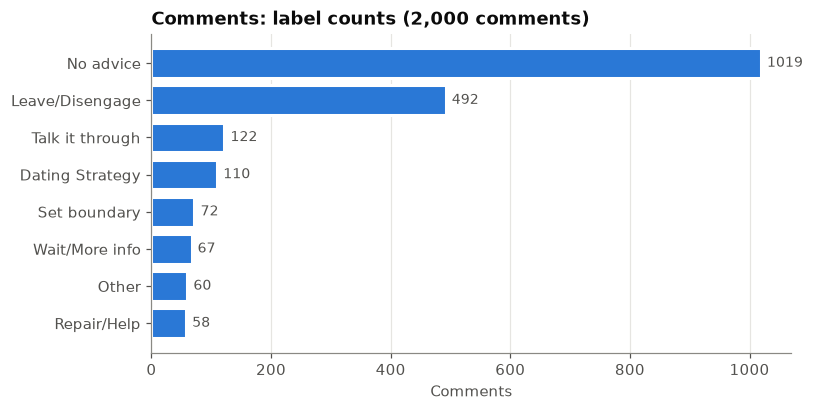

,items,share,median words
label,,,
Early Dating,356,44%,196
Breakups,30,4%,377
Reconciliation,7,1%,453
Communication,65,8%,329
Conflict,97,12%,495
Boundaries,106,13%,385
Trust,27,3%,403
Cheating,29,4%,488
Uncertainty,30,4%,324


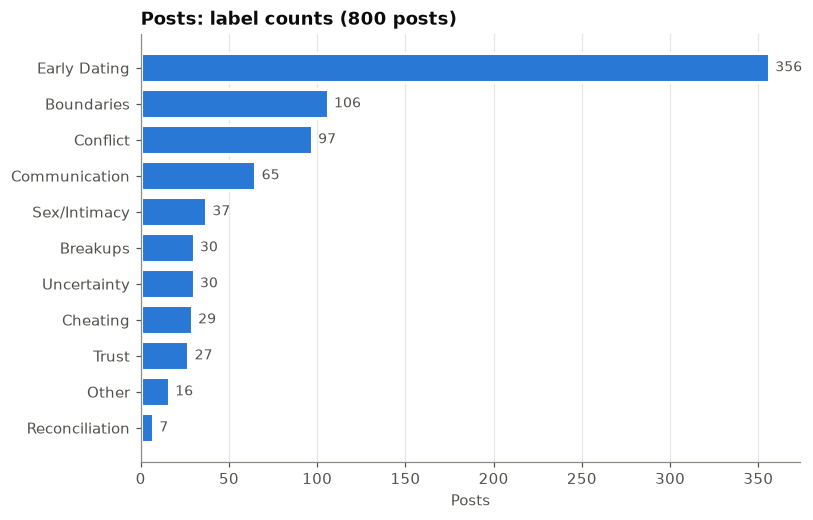

In [3]:
def label_overview(df, labels, what):
    counts = df["label"].value_counts().reindex(labels, fill_value=0)
    display(pd.DataFrame({"items": counts, "share": (counts / counts.sum()).map("{:.0%}".format),
                          "median words": df.groupby("label")["n_words"].median().reindex(labels).round().astype("Int64")}))
    order = counts.sort_values().index
    fig, ax = plt.subplots(figsize=(7.5, 0.33 * len(labels) + 1.2))
    ax.barh(order, counts[order], color=BLUE, edgecolor="white", linewidth=2)
    for i, lab in enumerate(order):
        ax.text(counts[lab] + counts.max() * 0.01, i, str(counts[lab]), va="center", color=INK_2, fontsize=9)
    ax.set_title(f"{what}: label counts ({len(df):,} {what.lower()})")
    ax.set_xlabel(what)
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()


label_overview(com, ADVICE_LABELS, "Comments")
label_overview(post, TOPIC_LABELS, "Posts")

- **Comments are very unbalanced:** *No advice* is 51% and *Leave/Disengage* 25%. The other six labels have only 3–6% each (58–122 comments).
- **Length is a clue:** *No advice* comments are short (median 26 words), while the advice labels have 47–98 words.
- **Posts:** *Early Dating* is 44%. *Reconciliation* (7 posts) and *Other* (16) are too small to learn.
- **Posts are long:** median 182–495 words, depending on the topic.

### 2.3 The two labelling batches
The files combine two labelling batches: the first annotation round (500 comments, 200 posts) and the new items (1,500 comments, 600 posts). Both were drawn with the same sampling code, so they should have similar label shares if they were labelled the same way.

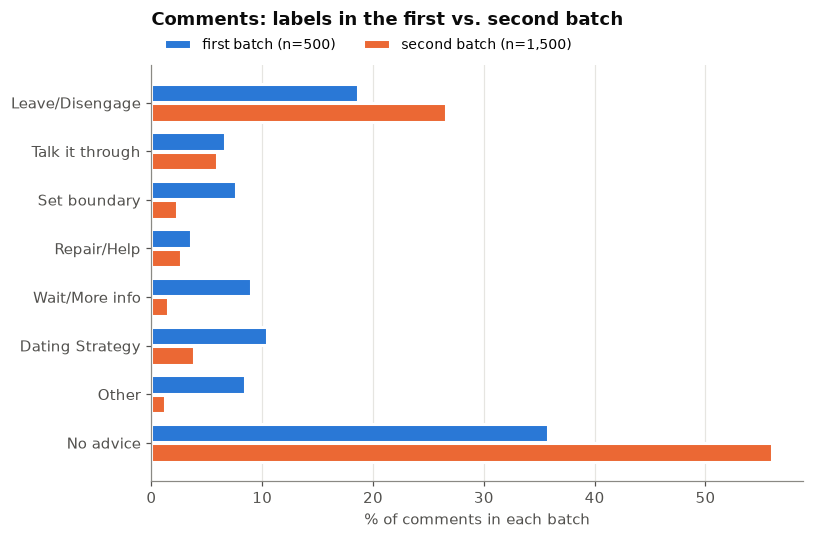

,first batch (n=500),"second batch (n=1,500)"
label,,
Leave/Disengage,18.6,26.6
Talk it through,6.6,5.9
Set boundary,7.6,2.3
Repair/Help,3.6,2.7
Wait/More info,9.0,1.5
Dating Strategy,10.4,3.9
Other,8.4,1.2
No advice,35.8,56.0


subreddit,r/dating_advice,r/datingadvice,r/relationship_advice,r/relationshipadvice,median words,with secondary label (%)
batch,,,,,,
first batch,32.0,18.0,18.0,32.0,41.0,14
second batch,32.0,18.0,18.0,32.0,41.0,4


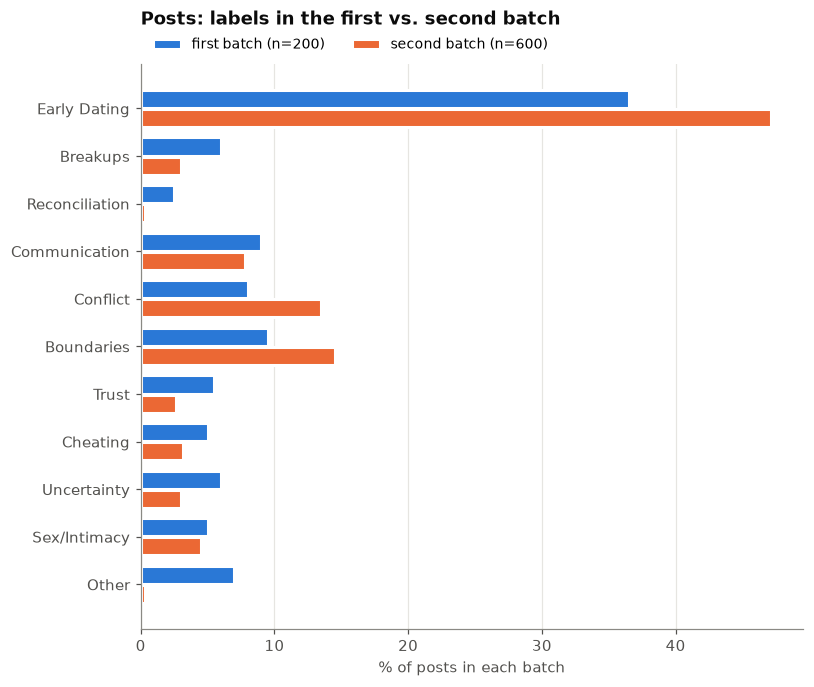

,first batch (n=200),second batch (n=600)
label,,
Early Dating,36.5,47.2
Breakups,6.0,3.0
Reconciliation,2.5,0.3
Communication,9.0,7.8
Conflict,8.0,13.5
Boundaries,9.5,14.5
Trust,5.5,2.7
Cheating,5.0,3.2
Uncertainty,6.0,3.0


subreddit,r/dating_advice,r/datingadvice,r/relationship_advice,r/relationshipadvice,median words,with secondary label (%)
batch,,,,,,
first batch,24.0,26.0,14.0,36.0,288.0,64
second batch,23.0,26.0,14.0,37.0,278.5,30


In [4]:
def plot_batch_shares(shares, what):
    """Grouped bars: share of each label in the first vs. the second batch."""
    y = np.arange(len(shares))
    fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(shares) + 1.4))
    for offset, column, color in [(-0.2, shares.columns[0], BLUE), (0.2, shares.columns[1], ORANGE)]:
        ax.barh(y + offset, shares[column] * 100, height=0.38, color=color, edgecolor="white", linewidth=2, label=column)
    ax.set_yticks(y, shares.index)
    ax.invert_yaxis()                       # same order as the table: first label at the top
    ax.set_title(f"{what}: labels in the first vs. second batch", pad=26)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
    ax.set_xlabel(f"% of {what.lower()} in each batch")
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()


def compare_batches(df, labels, what):
    sizes = df["batch"].value_counts()
    shares = pd.crosstab(df["label"], df["batch"], normalize="columns").reindex(labels, fill_value=0)
    shares.columns = [f"{b} (n={sizes[b]:,})" for b in shares.columns]
    plot_batch_shares(shares, what)
    display((shares * 100).round(1))
    mix = pd.crosstab(df["batch"], df["subreddit"], normalize="index").mul(100).round(0)
    mix["median words"] = df.groupby("batch")["n_words"].median()
    mix["with secondary label (%)"] = df.groupby("batch")["label_secondary"].apply(lambda s: round(s.notna().mean() * 100))
    display(mix)


compare_batches(com, ADVICE_LABELS, "Comments")
compare_batches(post, TOPIC_LABELS, "Posts")

**The texts are alike** (same subreddit mix and length), **but the two batches were labelled differently:**
- **Comments:** the second batch has far more *No advice* (56% vs. 36%) and *Leave/Disengage* (27% vs. 19%). It has far fewer *Wait/More info* (1.5% vs. 9%), *Other* (1.2% vs. 8%), *Dating Strategy* (4% vs. 10%) and *Set boundary* (2% vs. 8%).
- **Posts:** the second batch has more *Early Dating* (47% vs. 37%), *Conflict* and *Boundaries*, and almost never uses *Other* (0.3% vs. 7%).
- **Secondary labels:** the second batch uses them much less (4% vs. 14% of comments, 30% vs. 64% of posts).

The models learn from both batches together; the inconsistency is listed as a limitation in section 6.

## 3. Method

### 3.1 Label groupings
Merging similar labels gives each class more examples but less detail (the annotation guidelines allow it). Fewer classes are always easier, even for random guessing, so every grouping is compared with a **chance level**: random guesses in proportion to the class sizes.

| Comments | Change |
| :--- | :--- |
| **8 labels** | none (codebook) |
| **7 labels** | *Repair/Help* → *Talk it through* |
| **6 groups** | *Talk it through* + *Repair/Help* + *Set boundary* → **Stay & work on it** |
| **2 groups** | **Advice** vs. **No advice** |

| Posts | Change |
| :--- | :--- |
| **11 labels** | none (codebook) |
| **8 labels** | *Cheating* → *Trust*; *Uncertainty* and *Reconciliation* → *Other* (the label names in the transformer model's first results) |
| **4 situations** | the research question's situations: **Early Dating**, **Communication & Conflict**, **Trust & Cheating**, **Other** |

In [5]:
SAME_ADVICE = {label: label for label in ADVICE_LABELS}
ADVICE_GROUPINGS = {
    "8 labels": SAME_ADVICE,
    "7 labels": {**SAME_ADVICE, "Repair/Help": "Talk it through"},
    "6 groups": {**SAME_ADVICE, "Talk it through": "Stay & work on it", "Repair/Help": "Stay & work on it",
                 "Set boundary": "Stay & work on it"},
    "2 groups": {label: ("No advice" if label == "No advice" else "Advice") for label in ADVICE_LABELS},
}

SAME_TOPIC = {label: label for label in TOPIC_LABELS}
SITUATIONS = {"Early Dating": "Early Dating", "Communication": "Communication & Conflict",
              "Conflict": "Communication & Conflict", "Trust": "Trust & Cheating", "Cheating": "Trust & Cheating"}
TOPIC_GROUPINGS = {
    "11 labels": SAME_TOPIC,
    "8 labels": {**SAME_TOPIC, "Cheating": "Trust", "Uncertainty": "Other", "Reconciliation": "Other"},
    "4 situations": {label: SITUATIONS.get(label, "Other") for label in TOPIC_LABELS},
}

# One column per grouping, e.g. com["y_6 groups"]
for df, groupings in [(com, ADVICE_GROUPINGS), (post, TOPIC_GROUPINGS)]:
    for name, mapping in groupings.items():
        df[f"y_{name}"] = df["label"].map(mapping)
        assert df[f"y_{name}"].notna().all()

### 3.2 Shared 5-fold cross-validation
Every comment and post gets a `fold` number (1–5):
- **Threads are kept within one fold.** Otherwise the model could recognise a thread instead of the advice.
- **Each label is spread evenly over the folds.**

For fold *k*, the model is trained on the other four folds and predicts fold *k*. After five rounds, every item has one prediction from a model that never saw it. The folds are exported (section 6) so the transformer model uses exactly the same ones.

In [6]:
def assign_folds(df):
    """fold = 1..N_FOLDS; threads kept together, labels spread evenly."""
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    df["fold"] = 0
    for k, (_, idx) in enumerate(splitter.split(df, df["label"], groups=df["thread"]), start=1):
        df.loc[df.index[idx], "fold"] = k
    assert (df["fold"] > 0).all()
    assert df.groupby("thread")["fold"].nunique().max() == 1, "A thread is split across folds!"


assign_folds(com)
assign_folds(post)
display(pd.DataFrame({"comments": com["fold"].value_counts().sort_index(),
                      "posts": post["fold"].value_counts().sort_index()}).rename_axis("fold"))

,comments,posts
fold,,
1,400,160
2,400,160
3,400,160
4,400,160
5,400,160


### 3.3 Model and metrics
- **TF–IDF** turns a text into word weights. A word gets a high weight if it is frequent in this text but rare overall.
  - Variants tested: single words, word pairs (1–2-grams), character 2–5-grams, and stopwords kept or removed.
  - Always on: `min_df=2` (ignore words found in only one text) and `sublinear_tf` (dampens repeated words).
- **Logistic regression** learns a weight for every word and label, and predicts the label with the highest score.
  - `class_weight="balanced"` makes mistakes on small labels count more. Its effect is checked once in each experiment.
  - `C` ∈ {0.1, 1, 10} sets how cautious the weights are (smaller = more cautious). It is chosen on the folds.
- **Metrics:**
  - **precision:** how many items predicted as X really are X;
  - **recall:** how many real X items were found;
  - **F1:** combines precision and recall;
  - **support:** the number of items that really have the label;
  - **macro-F1:** the average F1 over all labels, each label counting equally. This is the main score, because the labels are unbalanced.

Experiments compare settings by the average macro-F1 over the 5 folds. The final results pool all out-of-fold predictions, which is what the transformer comparison uses; the two numbers are nearly identical.

In [7]:
# ---------- Text representations: name -> (function that builds the TF-IDF step, text column) ----------
def word_tfidf(**settings):
    return TfidfVectorizer(lowercase=True, sublinear_tf=True, min_df=2, **settings)


def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=True, sublinear_tf=True, min_df=2)


def words_and_chars():
    return FeatureUnion([("word", word_tfidf(ngram_range=(1, 2))), ("char", char_tfidf())])


APPROACHES = {
    "A. Words": (lambda: word_tfidf(ngram_range=(1, 1)), "text"),
    "B. Words + word pairs": (lambda: word_tfidf(ngram_range=(1, 2)), "text"),
    "C. Words + word pairs, no stopwords": (lambda: word_tfidf(ngram_range=(1, 2), stop_words="english"), "text"),
    "D. Characters": (char_tfidf, "text"),
    "E. Words + word pairs + characters": (words_and_chars, "text"),
}
C_GRID = [0.1, 1, 10]
REFERENCE = "Reference: always the most common label"


# ---------- Training ----------
def make_model(vectorizer, class_weight="balanced", C=1.0):
    return Pipeline([("tfidf", vectorizer),
                     ("clf", LogisticRegression(class_weight=class_weight, C=C, max_iter=5000, random_state=SEED))])


def folds_of(df):
    return PredefinedSplit(df["fold"].values - 1)


def tune(vectorizer, df, label_col, text_col="text", class_weight="balanced"):
    """Choose C on the shared folds (average macro-F1 over the 5 folds)."""
    search = GridSearchCV(make_model(vectorizer, class_weight), {"clf__C": C_GRID}, scoring="f1_macro",
                          cv=folds_of(df), n_jobs=-1, refit=False)
    return search.fit(df[text_col], df[label_col])


def summarise(search):
    i = search.best_index_
    return [search.best_score_, search.cv_results_["std_test_score"][i], search.best_params_["clf__C"]]


# ---------- Experiment 1: text representations ----------
def experiment_1(df, approaches, label_col):
    rows = {name: summarise(tune(make_vectorizer(), df, label_col, text_col))
            for name, (make_vectorizer, text_col) in approaches.items()}
    table = pd.DataFrame.from_dict(rows, orient="index", columns=["macro-F1", "std", "best C"])
    best = table["macro-F1"].idxmax()
    make_vectorizer, text_col = approaches[best]
    table.loc[f"{best.split('.')[0]} without class weighting"] = summarise(
        tune(make_vectorizer(), df, label_col, text_col, class_weight=None))
    ref = cross_val_score(DummyClassifier(strategy="most_frequent"), df["text"], df[label_col],
                          cv=folds_of(df), scoring="f1_macro")
    table.loc[REFERENCE] = [ref.mean(), ref.std(), np.nan]
    return table.rename_axis("approach").round(3), best


def plot_experiment_1(table, title):
    df = table.drop(index=REFERENCE).sort_values("macro-F1")
    ref = table.loc[REFERENCE, "macro-F1"]
    fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(df) + 1.4))
    ax.barh(df.index, df["macro-F1"], xerr=df["std"], color=BLUE, edgecolor="white", linewidth=2,
            error_kw={"ecolor": INK_MUTED, "elinewidth": 1, "capsize": 3})
    ax.axvline(ref, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.text(ref + 0.005, len(df) - 0.45, "always the most common label", color=INK_2, fontsize=8.5, va="bottom")
    for i, v in enumerate(df["macro-F1"]):
        ax.text(0.01, i, f"{v:.2f}", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_title(title, pad=14)
    ax.set_xlabel("Macro-F1 (mean of 5 folds; line = ± 1 std)")
    ax.set_xlim(0, max(0.5, (df["macro-F1"] + df["std"]).max() + 0.05))
    ax.xaxis.grid(True); ax.set_axisbelow(True)
    plt.tight_layout(); plt.show()


# ---------- Experiment 2 and final results: label groupings ----------
def evaluate_groupings(df, groupings, make_vectorizer, text_col):
    """Per grouping: choose C on the folds, then predict every item from the model trained on the other folds."""
    fold_ids = df["fold"].values
    rows, best_C = [], {}
    for name in groupings:
        y_col = f"y_{name}"
        y = df[y_col].values
        C = tune(make_vectorizer(), df, y_col, text_col).best_params_["clf__C"]
        best_C[name] = C
        pred = cross_val_predict(make_model(make_vectorizer(), C=C), df[text_col], y, cv=folds_of(df), n_jobs=-1)
        df[f"cv_pred_{name}"] = pred
        chance = cross_val_predict(DummyClassifier(strategy="stratified", random_state=SEED), df[text_col], y, cv=folds_of(df))
        majority = cross_val_predict(DummyClassifier(strategy="most_frequent"), df[text_col], y, cv=folds_of(df))
        per_fold = [f1_score(y[fold_ids == k], pred[fold_ids == k], average="macro", zero_division=0)
                    for k in range(1, N_FOLDS + 1)]
        macro = f1_score(y, pred, average="macro", zero_division=0)
        chance_f1 = f1_score(y, chance, average="macro", zero_division=0)
        rows.append({"grouping": name, "classes": len(set(y)), "smallest class": pd.Series(y).value_counts().min(),
                     "macro-F1": macro, "std across folds": np.std(per_fold), "accuracy": accuracy_score(y, pred),
                     "chance macro-F1": chance_f1, "above chance": macro - chance_f1,
                     "always most common: macro-F1": f1_score(y, majority, average="macro", zero_division=0),
                     "best C": C})
    return pd.DataFrame(rows).set_index("grouping").round(3), best_C


def plot_groupings(table, title):
    fig, ax = plt.subplots(figsize=(7.5, 0.75 * len(table) + 0.9))
    y = np.arange(len(table))
    ax.barh(y + 0.2, table["macro-F1"], height=0.38, color=BLUE, edgecolor="white", linewidth=2, label="Model")
    ax.barh(y - 0.2, table["chance macro-F1"], height=0.38, color=ORANGE, edgecolor="white", linewidth=2, label="Chance level")
    for i, (m, c) in enumerate(zip(table["macro-F1"], table["chance macro-F1"])):
        ax.text(m + 0.01, i + 0.2, f"{m:.2f}", va="center", color=INK_2, fontsize=9)
        ax.text(c + 0.01, i - 0.2, f"{c:.2f}", va="center", color=INK_2, fontsize=9)
    ax.set_yticks(y, table.index)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Macro-F1 (all out-of-fold predictions)")
    ax.set_xlim(0, 1); ax.xaxis.grid(True); ax.set_axisbelow(True)
    ax.legend(loc="upper right")
    plt.tight_layout(); plt.show()


# ---------- Per-label results ----------
def label_order(mapping):
    """The labels of a grouping in codebook order, with 'Other' and 'No advice' moved to the end."""
    labels = list(dict.fromkeys(mapping.values()))
    last = [l for l in ("Other", "No advice") if l in labels]
    return [l for l in labels if l not in last] + last


def per_label_table(y_true, y_pred, labels):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    table = pd.DataFrame({"precision": p, "recall": r, "F1": f, "support": s}, index=labels)
    table.loc["macro average"] = [p.mean(), r.mean(), f.mean(), s.sum()]
    return table.round(2).astype({"support": int})


def show_per_label_tables(df, groupings):
    for name, mapping in groupings.items():
        display(Markdown(f"**{name}**"))
        display(per_label_table(df[f"y_{name}"], df[f"cv_pred_{name}"], label_order(mapping)))


def plot_confusion(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    n = len(labels)
    fig, ax = plt.subplots(figsize=(0.8 * n + 3.2, 0.62 * n + 2.0))
    ax.imshow(share, cmap=SEQ_BLUES, vmin=0, vmax=1)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if share[i, j] > 0.55 else (INK if cm[i, j] else INK_MUTED))
    ax.set_xticks(range(n), labels, rotation=35, ha="right")
    ax.set_yticks(range(n), labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Annotated")
    ax.set_title(title, pad=20)
    ax.text(0, 1.015, "Numbers = counts · shade = share of the annotated row", transform=ax.transAxes,
            va="bottom", color=INK_2, fontsize=8.5)
    for side in ax.spines.values():
        side.set_visible(False)
    plt.tight_layout(); plt.show()


# ---------- Inside the model ----------
def top_words(df, make_vectorizer, text_col, y_col, C, n=12):
    """Train on all items and list the n words / word pairs with the highest weight per label."""
    model = make_model(make_vectorizer(), C=C).fit(df[text_col], df[y_col])
    vectorizer, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    names = vectorizer.get_feature_names_out().astype(str)
    weights = clf.coef_
    if isinstance(vectorizer, FeatureUnion):            # words + characters: show only the word part
        keep = np.char.startswith(names, "word__")
        names, weights = np.char.replace(names[keep], "word__", ""), weights[:, keep]
    return pd.DataFrame({label: names[np.argsort(weights[k])[::-1][:n]] for k, label in enumerate(clf.classes_)},
                        index=pd.RangeIndex(1, n + 1, name="rank"))


# ---------- Mistakes ----------
def look_at_mistakes(df, grouping, mapping, show_col, show_name, n_examples=10):
    y_col, p_col = f"y_{grouping}", f"cv_pred_{grouping}"
    errors = df[df[y_col] != df[p_col]]
    print(f"Wrong predictions ({grouping}): {len(errors):,} of {len(df):,}\n")
    print("Most common confusions:")
    display(errors.groupby([y_col, p_col]).size().sort_values(ascending=False).head(8)
            .rename("count").reset_index().rename(columns={y_col: "annotated", p_col: "predicted"}))
    secondary = errors["label_secondary"].map(mapping)
    has_secondary = secondary.notna()
    print(f"Mistakes on items with a secondary label: {has_secondary.sum()}; "
          f"in {(errors.loc[has_secondary, p_col] == secondary[has_secondary]).sum()} of them the model predicted that secondary label.")
    if SHOW_TEXT_EXAMPLES:
        sample = errors.sample(min(n_examples, len(errors)), random_state=SEED)
        display(sample.assign(**{show_name: sample[show_col].map(snippet)})[[y_col, p_col, show_name]]
                .rename(columns={y_col: "annotated", p_col: "predicted"}).reset_index(drop=True))

---
## 4. Comments: advice type

### 4.1 Experiment 1: text representations
Five representations on the 8 labels, each with balanced class weights and the best `C`. The best one is also run without class weighting.

| Approach | Description |
| :--- | :--- |
| A. Words | single words |
| B. Words + word pairs | 1–2-grams |
| C. Words + word pairs, no stopwords | like B, without common English words |
| D. Characters | 2–5-character runs |
| E. Words + word pairs + characters | B and D combined |

,macro-F1,std,best C
approach,,,
A. Words,0.441,0.056,10.0
B. Words + word pairs,0.457,0.047,1.0
"C. Words + word pairs, no stopwords",0.404,0.057,10.0
D. Characters,0.451,0.050,1.0
E. Words + word pairs + characters,0.482,0.049,1.0
E without class weighting,0.329,0.044,10.0
Reference: always the most common label,0.084,0.000,NaN


Best approach: E. Words + word pairs + characters


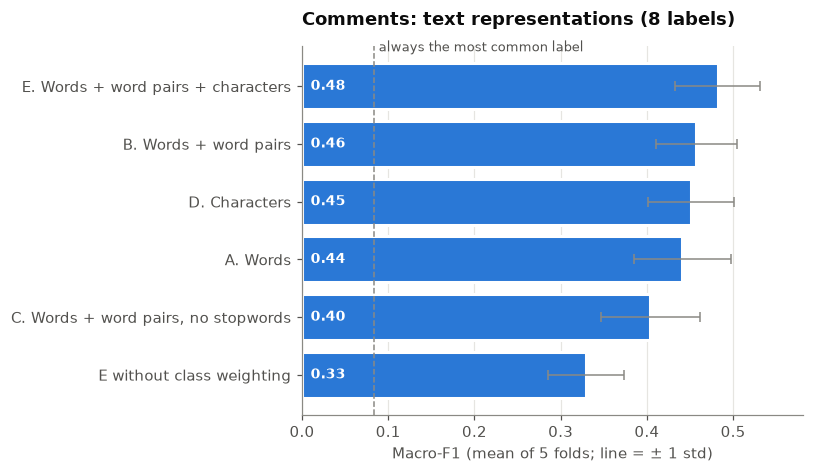

In [8]:
exp1_A, BEST_A = experiment_1(com, APPROACHES, "y_8 labels")
display(exp1_A)
print(f"Best approach: {BEST_A}")
plot_experiment_1(exp1_A, "Comments: text representations (8 labels)")

- **E (words + word pairs + characters) is best: 0.48.** Word pairs (0.46), characters (0.45) and single words (0.44) are close; E's lead is within one standard deviation.
- **Removing stopwords hurts** (0.46 → 0.40). *you*, *if* and *do you* separate advice from stories and questions.
- **Class weighting is essential:** E without it drops to 0.33.
- **All approaches are far above always predicting *No advice*** (0.08).

### 4.2 Experiment 2 and results: label groupings
The best representation on each grouping. Every item is predicted by the model trained on the other four folds.

,classes,smallest class,macro-F1,std across folds,accuracy,chance macro-F1,above chance,always most common: macro-F1,best C
grouping,,,,,,,,,
8 labels,8,58,0.484,0.049,0.711,0.125,0.359,0.084,1
7 labels,7,60,0.472,0.059,0.711,0.149,0.323,0.096,1
6 groups,6,60,0.486,0.041,0.722,0.174,0.312,0.113,1
2 groups,2,981,0.836,0.026,0.836,0.500,0.336,0.338,10


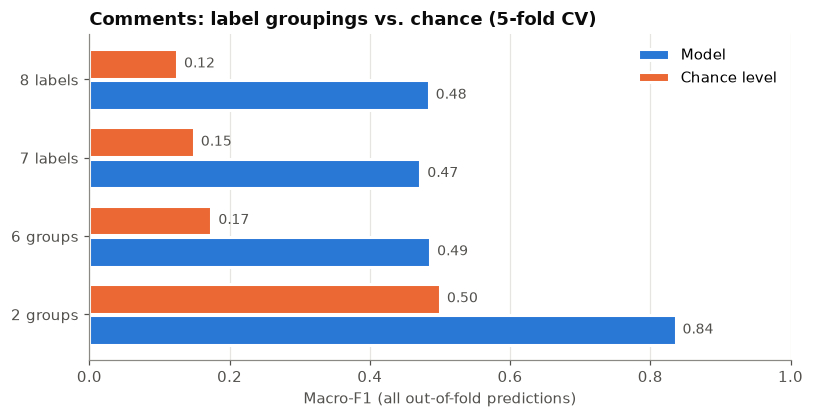

In [9]:
results_A, best_C_A = evaluate_groupings(com, ADVICE_GROUPINGS, *APPROACHES[BEST_A])
display(results_A)
plot_groupings(results_A, "Comments: label groupings vs. chance (5-fold CV)")

- **8 labels: macro-F1 0.48** (std 0.05 across folds, accuracy 0.71), which is **0.36 above chance**.
- **Merging hardly changes the score:** 7 labels score 0.47 and 6 groups 0.49, with no larger gain above chance. **The 8 original labels stay the main result.**
- **Advice vs. no advice: 0.84** (chance 0.50).

### 4.3 Per-label precision, recall and F1
Support is the number of comments that really have the label; labels with small support have unreliable scores. In the confusion matrices, rows are the annotated labels, columns the predictions, and the diagonal holds the correct predictions.

**8 labels**

,precision,recall,F1,support
Leave/Disengage,0.63,0.76,0.69,492
Talk it through,0.48,0.61,0.54,122
Set boundary,0.62,0.29,0.40,72
Repair/Help,0.57,0.52,0.54,58
Wait/More info,0.40,0.15,0.22,67
Dating Strategy,0.48,0.64,0.54,110
Other,0.25,0.07,0.11,60
No advice,0.86,0.82,0.84,1019
macro average,0.54,0.48,0.48,2000


**7 labels**

,precision,recall,F1,support
Leave/Disengage,0.63,0.74,0.68,492
Talk it through,0.48,0.63,0.55,180
Set boundary,0.57,0.24,0.33,72
Wait/More info,0.45,0.15,0.22,67
Dating Strategy,0.49,0.60,0.54,110
Other,0.31,0.08,0.13,60
No advice,0.86,0.83,0.84,1019
macro average,0.54,0.47,0.47,2000


**6 groups**

,precision,recall,F1,support
Leave/Disengage,0.65,0.73,0.69,492
Stay & work on it,0.54,0.68,0.60,252
Wait/More info,0.35,0.09,0.14,67
Dating Strategy,0.50,0.55,0.53,110
Other,0.40,0.07,0.11,60
No advice,0.86,0.83,0.84,1019
macro average,0.55,0.49,0.49,2000


**2 groups**

,precision,recall,F1,support
Advice,0.82,0.86,0.84,981
No advice,0.86,0.81,0.84,1019
macro average,0.84,0.84,0.84,2000


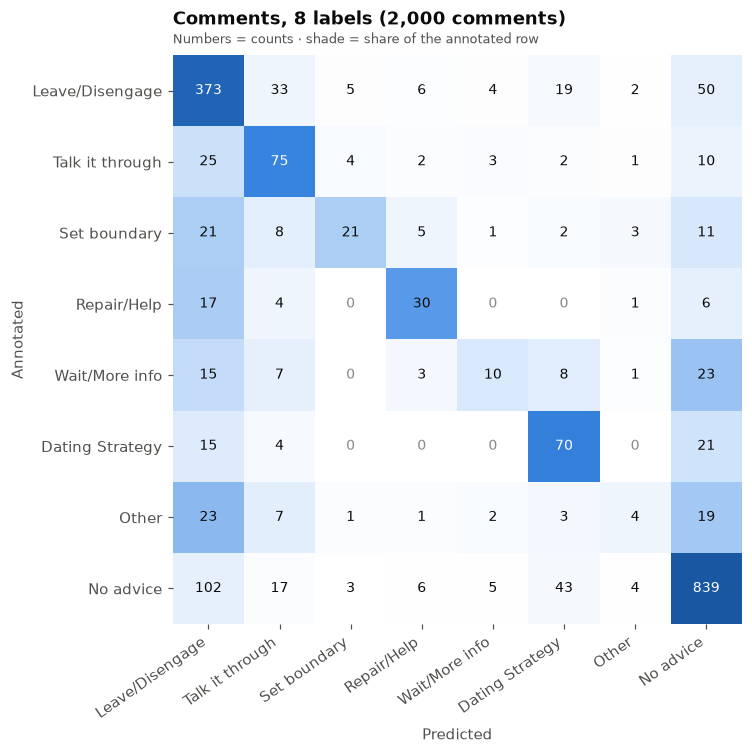

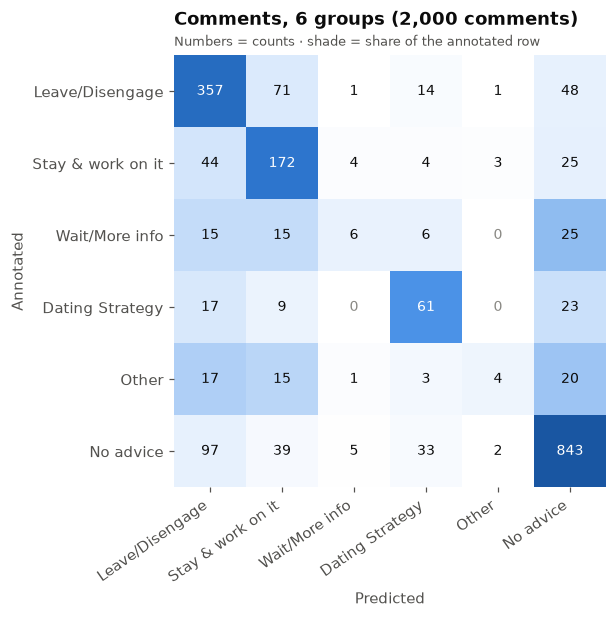

In [10]:
show_per_label_tables(com, ADVICE_GROUPINGS)
plot_confusion(com["y_8 labels"], com["cv_pred_8 labels"], ADVICE_LABELS, f"Comments, 8 labels ({len(com):,} comments)")
plot_confusion(com["y_6 groups"], com["cv_pred_6 groups"], label_order(ADVICE_GROUPINGS["6 groups"]),
               f"Comments, 6 groups ({len(com):,} comments)")

- **Good:**
  - *No advice* (F1 0.84);
  - *Leave/Disengage* (0.69), with recall 0.76 but precision 0.63, so it is over-predicted;
  - *Talk it through*, *Repair/Help* and *Dating Strategy* (0.54 each).
- **Poor:** *Set boundary* (0.40), *Wait/More info* (0.22) and *Other* (0.11). The model rarely predicts them (recall 0.07–0.29).
- **6 groups:** the merged *Stay & work on it* reaches 0.60.
- **Biggest confusion: *No advice* ↔ *Leave/Disengage*** (102 and 50 comments). *No advice* comments are also often taken for *Dating Strategy* (43).

### 4.4 Top words and mistakes (8 labels)
The 12 words or word pairs with the highest weight per label (model trained on all comments; word part only), followed by the most common confusions, accuracy by comment length and 10 random wrong predictions.

In [11]:
display(top_words(com, *APPROACHES[BEST_A], "y_8 labels", best_C_A["8 labels"]))

look_at_mistakes(com, "8 labels", ADVICE_GROUPINGS["8 labels"], "bodyText", "comment")
length = pd.cut(com["n_words"], [0, 20, 60, np.inf], labels=["short (≤20 words)", "medium (21–60)", "long (>60)"]).rename("length")
correct = com["cv_pred_8 labels"] == com["y_8 labels"]
print("\nAccuracy by comment length:")
display(correct.groupby(length, observed=True).agg(comments="size", accuracy="mean").round(2))

,Dating Strategy,Leave/Disengage,No advice,Other,Repair/Help,Set boundary,Talk it through,Wait/More info
rank,,,,,,,,
1,date,move on,man,cheat,therapy,boundaries,tell,are you
2,women,move,like,yourself,therapist,set,tell him,do you
3,her out,leave,to the,the,needs,tell him,tell her,updates
4,apps,you,was,dinner,she needs,he to,talk,we need
5,into,break,lol,love yourself,counseling,your,him,what is
6,if you,someone who,being,ll need,help,boundary,about,how old
7,go on,break up,for me,to love,go to,what you,him you,are
8,the date,with,good,love,she,mom,talk to,do
9,get off,on,girl,to go,both,without her,about it,old are


Wrong predictions (8 labels): 578 of 2,000

Most common confusions:


,annotated,predicted,count
0,No advice,Leave/Disengage,102
1,Leave/Disengage,No advice,50
2,No advice,Dating Strategy,43
3,Leave/Disengage,Talk it through,33
4,Talk it through,Leave/Disengage,25
5,Other,Leave/Disengage,23
6,Wait/More info,No advice,23
7,Dating Strategy,No advice,21


Mistakes on items with a secondary label: 64; in 32 of them the model predicted that secondary label.


,annotated,predicted,comment
0,Leave/Disengage,No advice,U SHOULD GO is the answer you should be accepting and ps I am not shouting I am saying this 😊😇
1,Leave/Disengage,No advice,"i mean if youre very upfront about it being just for fun and non commital, and the other party accepts this conditions explicitly, i dont see why not.…"
2,No advice,Leave/Disengage,It's not easy for anyone out there. You're cute so it's not your looks. I've always been able to get dates but end up with the same BS. It's either sl…
3,No advice,Dating Strategy,"As an outdoor athlete myself, I think a lot of people focus too much on portrayals of easy sex from mass media. I have been approached by a lot of bro…"
4,Repair/Help,Leave/Disengage,"Some of these comments makes it seem like this should be normal, but it def is not a healthy and normal behaviour. Social media provides instant grati…"
5,Talk it through,Set boundary,dude you gotta be honest with yourself. you have trust issues and its ok i don't blame you for having them but you cannot say you trust her because yo…
6,Other,Dating Strategy,Roughly speaking. By far most guys can absolutely be attractive. But there are real things to do. I little grooming sure. But mostly it's about who yo…
7,Other,Leave/Disengage,If it felt off.. listen to your gut. You are posting because you know canceling is the right call.
8,No advice,Repair/Help,"I'm glad things have worked out well so far, and I hope they continue to do so and that your wife gets the help she needs to be able to live more comf…"
9,No advice,Leave/Disengage,Uk what girl im so proud of you. I have always been going to movies with people and last year i really wanted to watch little women but none of my fri…



Accuracy by comment length:


,comments,accuracy
length,,
short (≤20 words),522,0.84
medium (21–60),736,0.74
long (>60),742,0.59


- **Top words are mostly sensible:**
  - *Dating Strategy*: date, women, apps.
  - *Leave/Disengage*: move on, leave, break up.
  - *Talk it through*: tell him, talk, conversation.
  - *Set boundary*: boundaries, set.
  - *Repair/Help*: therapy, counseling.
  - *Wait/More info*: questions (*are you*, *do you*) and *updates*.
  - *No advice*: stories and reactions (*man*, *lol*, *girl*).
  - Accidental words from single threads remain, e.g. *dinner* and *clean house* (Other) and *you paying* (Wait/More info).
- **578 of 2,000 comments are wrong.** Accuracy falls with length: 0.84 for short comments, 0.74 for medium and 0.59 for long ones.
- **Partly right:** in 32 of the 64 errors on comments with a secondary label, the model predicted that second label.
- **Typical problems in the sample:**
  - **unusual wording** (row 0: *"U SHOULD GO"* is read as *No advice*);
  - **stories and support read as advice** (rows 2 and 9 become *Leave*; row 8, *"…gets the help she needs"*, becomes *Repair/Help*);
  - **topic words pulling towards *Dating Strategy*** (rows 3 and 6);
  - **debatable labels** (row 1 is labelled *Leave* but says *"I don't see why not"*; in row 7 the model's *Leave* is defensible).

---
## 5. Posts: topic
The same steps for posts. Posts are much longer than comments (median roughly 270 words vs. 41) and there are fewer of them.

### 5.1 Experiment 1: text representations
The same five approaches on the 11 labels, plus **F. Title only** (words + word pairs from the title alone).

,macro-F1,std,best C
approach,,,
A. Words,0.345,0.027,0.1
B. Words + word pairs,0.338,0.018,0.1
"C. Words + word pairs, no stopwords",0.377,0.011,1.0
D. Characters,0.338,0.030,1.0
E. Words + word pairs + characters,0.333,0.035,0.1
F. Title only (words + word pairs),0.250,0.021,1.0
C without class weighting,0.198,0.039,10.0
Reference: always the most common label,0.056,0.000,NaN


Best approach: C. Words + word pairs, no stopwords


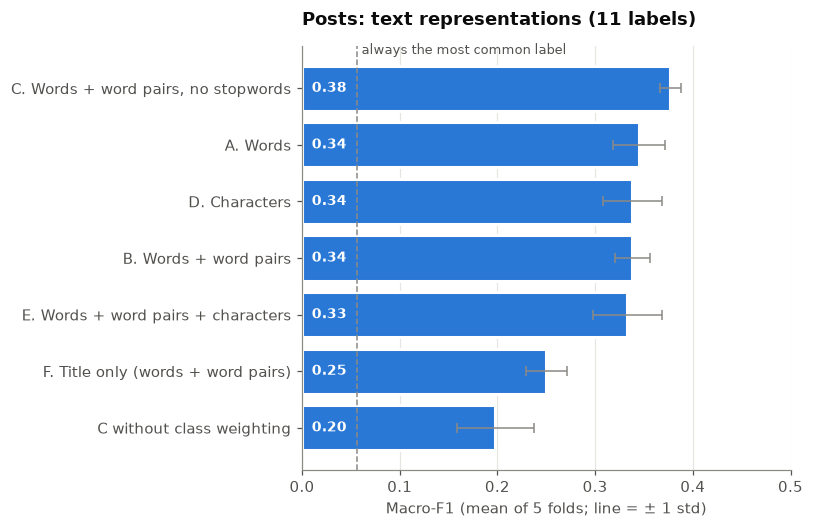

In [12]:
POST_APPROACHES = {**APPROACHES,
                   "F. Title only (words + word pairs)": (lambda: word_tfidf(ngram_range=(1, 2)), "title_text")}
exp1_B, BEST_B = experiment_1(post, POST_APPROACHES, "y_11 labels")
display(exp1_B)
print(f"Best approach: {BEST_B}")
plot_experiment_1(exp1_B, "Posts: text representations (11 labels)")

- **C (word pairs without stopwords) is best: 0.38**, ahead of words (0.35), word pairs (0.34) and characters (0.33–0.34). Unlike for comments, removing stopwords helps here: a post's topic lives in content words, and long posts contain many filler words.
- **The title alone is clearly worse** (0.25). Most of the topic information is in the post text.
- **Class weighting is essential again:** 0.20 without it.

### 5.2 Experiment 2 and results: label groupings

,classes,smallest class,macro-F1,std across folds,accuracy,chance macro-F1,above chance,always most common: macro-F1,best C
grouping,,,,,,,,,
11 labels,11,7,0.381,0.011,0.654,0.101,0.279,0.056,1.0
8 labels,8,30,0.439,0.026,0.636,0.120,0.319,0.077,0.1
4 situations,4,56,0.624,0.042,0.700,0.220,0.404,0.154,0.1


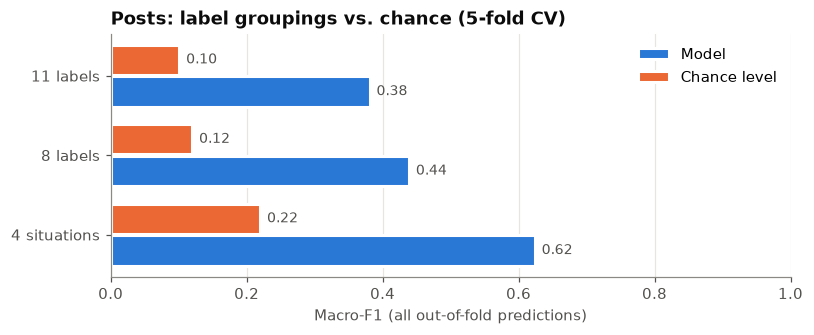

In [13]:
results_B, best_C_B = evaluate_groupings(post, TOPIC_GROUPINGS, *POST_APPROACHES[BEST_B])
display(results_B)
plot_groupings(results_B, "Posts: label groupings vs. chance (5-fold CV)")

- **11 labels 0.38, 8 labels 0.44, 4 situations 0.62.** Above chance that is +0.28, +0.32 and +0.40.
- **Unlike for comments, merging really helps here.** The small topics overlap (Trust/Cheating, Communication/Conflict), so merged groups are easier to tell apart, not just fewer.
- **Use 4 situations** for the research question and **8 labels** to compare with the transformer model.

### 5.3 Per-label precision, recall and F1

**11 labels**

,precision,recall,F1,support
Early Dating,0.83,0.92,0.88,356
Breakups,0.40,0.07,0.11,30
Reconciliation,0.00,0.00,0.00,7
Communication,0.47,0.32,0.38,65
Conflict,0.46,0.71,0.56,97
Boundaries,0.45,0.52,0.48,106
Trust,0.67,0.22,0.33,27
Cheating,0.60,0.41,0.49,29
Uncertainty,0.48,0.33,0.39,30
Sex/Intimacy,0.57,0.54,0.56,37


**8 labels**

,precision,recall,F1,support
Early Dating,0.84,0.90,0.87,356
Breakups,0.18,0.07,0.10,30
Communication,0.37,0.26,0.31,65
Conflict,0.50,0.69,0.58,97
Boundaries,0.54,0.35,0.43,106
Trust,0.42,0.57,0.48,56
Sex/Intimacy,0.45,0.59,0.51,37
Other,0.30,0.19,0.23,53
macro average,0.45,0.45,0.44,800


**4 situations**

,precision,recall,F1,support
Early Dating,0.83,0.94,0.88,356
Communication & Conflict,0.54,0.65,0.59,162
Trust & Cheating,0.54,0.54,0.54,56
Other,0.62,0.40,0.49,226
macro average,0.63,0.63,0.62,800


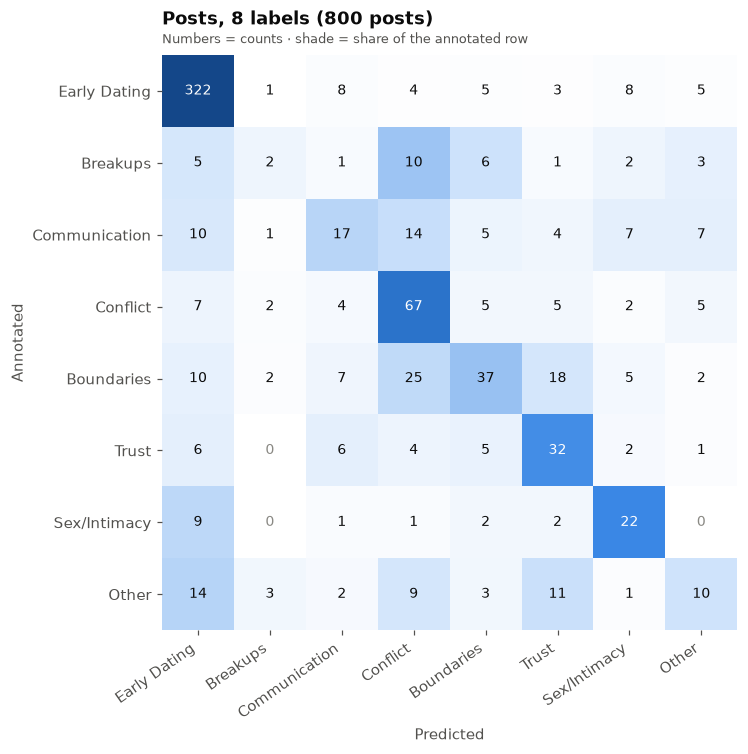

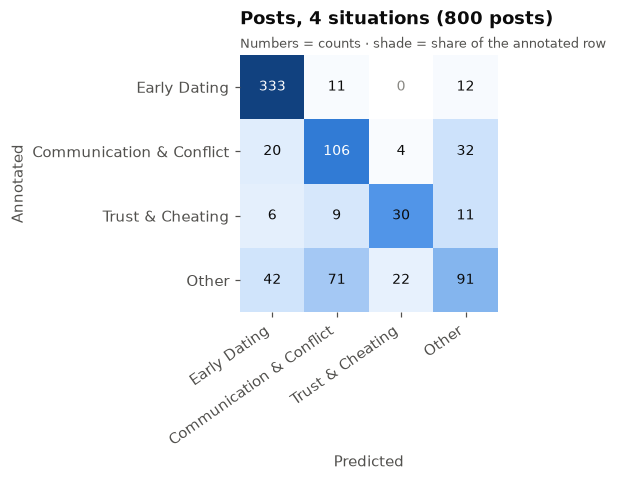

In [14]:
show_per_label_tables(post, TOPIC_GROUPINGS)
plot_confusion(post["y_8 labels"], post["cv_pred_8 labels"], label_order(TOPIC_GROUPINGS["8 labels"]),
               f"Posts, 8 labels ({len(post):,} posts)")
plot_confusion(post["y_4 situations"], post["cv_pred_4 situations"], label_order(TOPIC_GROUPINGS["4 situations"]),
               f"Posts, 4 situations ({len(post):,} posts)")

- ***Early Dating* is found very reliably** (F1 0.87–0.88, recall 0.90–0.94).
- **8 labels:**
  - medium: *Conflict* (0.58), *Sex/Intimacy* (0.51), *Trust* (0.48), *Boundaries* (0.43);
  - weak: *Communication* (0.31) and *Other* (0.23);
  - *Breakups* is almost never found (2 of 30).
- **11 labels:** *Reconciliation* and *Other* are never found.
- **4 situations:** Early Dating 0.88, Communication & Conflict 0.59, Trust & Cheating 0.54, Other 0.49.
- **Confusion matrix:** *Other* posts are spread over all situations (71 go to Communication & Conflict, 42 to Early Dating).

### 5.4 Top words and mistakes (8 labels)
The examples show the post title only.

In [15]:
display(top_words(post, *POST_APPROACHES[BEST_B], "y_8 labels", best_C_B["8 labels"]))
look_at_mistakes(post, "8 labels", TOPIC_GROUPINGS["8 labels"], "title", "post title")

,Boundaries,Breakups,Communication,Conflict,Early Dating,Other,Sex/Intimacy,Trust
rank,,,,,,,,
1,boundaries,end,boyfriend,argument,date,marriage,sex,cheated
2,friend,breaking,bf,work,dating,visa,intimacy,trust
3,sister,break bf,ask,home,men,future,having sex,lying
4,husband,guys ended,makes,living,guy,lifestyle,porn,saw
5,uncomfortable,leave,open,upset,women,life,sexually,told
6,son,grass,shuts,cooking,apps,married,kissing,lie
7,friends,relationship thought,joke,job,girl,idea,casual,wife
8,boundary,pay,tldr,house,dates,settle,sexual,post
9,baby,house,worried,taking,interested,incompatible,cuddle,phone


Wrong predictions (8 labels): 291 of 800

Most common confusions:


,annotated,predicted,count
0,Boundaries,Conflict,25
1,Boundaries,Trust,18
2,Communication,Conflict,14
3,Other,Early Dating,14
4,Other,Trust,11
5,Breakups,Conflict,10
6,Communication,Early Dating,10
7,Boundaries,Early Dating,10


Mistakes on items with a secondary label: 138; in 56 of them the model predicted that secondary label.


,annotated,predicted,post title
0,Conflict,Other,I [26F] think my boyfriend [29M] wants to get married for money and I don’t know what to do next
1,Communication,Conflict,"My 35F husband 41M told me he ""is not my maid"" when I asked why he didn't clean up after our sick daughter. How can we address this postpartum imbalan…"
2,Boundaries,Trust,"My husband [35m] betrayed me [35f] during one of the most painful moments of my life, then gaslit me while I was miscarrying"
3,Other,Early Dating,Are stretch marks big deal for men?
4,Boundaries,Trust,The guy I was talking to [25M] asked for space in October. It’s January and I [25F] haven’t heard from him since.
5,Boundaries,Trust,My [20M] girlfriend [20F] admitted she‘s actively flirting with guys on holiday.
6,Early Dating,Boundaries,No more Single Moms for me :(
7,Boundaries,Trust,My girlfriend [47F] Posted this on Facebook. Should I be offended? [51M]
8,Other,Trust,My [32F] husband [32M] lost touch with reality and I am worried about us
9,Trust,Communication,My boyfriend [29M] wants to go on a trip with his female bestfriend [29F] alone.


- **Top words are clear topic signals:**
  - *Trust*: cheated, lying, phone, messages.
  - *Sex/Intimacy*: sex, intimacy, porn.
  - *Early Dating*: date, dating, apps.
  - *Conflict*: argument, home, cooking, chores.
  - *Breakups*: breaking, leave, regret.
  - *Other*: marriage, visa, future, settle (life plans).
  - *Boundaries*: boundaries, friend, sister, mom, uncomfortable (people around the couple).
  - *Communication* has vaguer words, which matches its low F1.
- **291 of 800 posts are wrong.** In 56 of the 138 errors on posts with a secondary topic, the model predicted that topic.
- **The most common errors are between overlapping topics:** *Boundaries* → *Conflict* (25) and → *Trust* (18), *Communication* → *Conflict* (14).
- **The sample shows many borderline cases,** e.g. row 2 (*"husband betrayed me… gaslit me"*), row 5 (*"girlfriend… actively flirting with guys"*) and row 9 (*"trip with his female bestfriend alone"*). These could reasonably be either *Boundaries* or *Trust*.

---
## 6. Export and summary

### 6.1 Export for the transformer model
These files go to `data/model_outputs/`. They contain IDs and labels only, no Reddit text, and they are shared directly rather than committed to GitHub.

| File | Content |
| :--- | :--- |
| `comment_split.csv` | the 2,000 comments with their `fold` (1–5), `label`, `label_secondary` and every grouping (`y_…`) |
| `post_split.csv` | the same for the 800 posts |
| `comment_cv_predictions_baseline.csv` | the baseline's out-of-fold prediction for every comment in every grouping (`cv_pred_…`) |
| `post_cv_predictions_baseline.csv` | the same for the posts |

In [16]:
def split_file(df, groupings, id_cols):
    return df[id_cols + ["subreddit", "fold", "label", "label_secondary"] + [f"y_{g}" for g in groupings]]


def cv_predictions_file(df, groupings, id_cols):
    return df[id_cols + ["fold"] + [f"y_{g}" for g in groupings] + [f"cv_pred_{g}" for g in groupings]]


exports = {
    "comment_split.csv": split_file(com, ADVICE_GROUPINGS, ["submissionId", "parentPostId"]),
    "post_split.csv": split_file(post, TOPIC_GROUPINGS, ["submissionId"]),
    "comment_cv_predictions_baseline.csv": cv_predictions_file(com, ADVICE_GROUPINGS, ["submissionId", "parentPostId"]),
    "post_cv_predictions_baseline.csv": cv_predictions_file(post, TOPIC_GROUPINGS, ["submissionId"]),
}
for filename, df in exports.items():
    assert not {"bodyText", "title", "text", "title_text"} & set(df.columns)   # never export Reddit text
    df.to_csv(OUT_DIR / filename, index=False)
    print(f"Saved {filename:<40} {len(df):>5,} rows -> {(OUT_DIR / filename).relative_to(ROOT).as_posix()}")

Saved comment_split.csv                        2,000 rows -> data/model_outputs/comment_split.csv
Saved post_split.csv                             800 rows -> data/model_outputs/post_split.csv
Saved comment_cv_predictions_baseline.csv      2,000 rows -> data/model_outputs/comment_cv_predictions_baseline.csv
Saved post_cv_predictions_baseline.csv           800 rows -> data/model_outputs/post_cv_predictions_baseline.csv


### 6.2 Summary

**Results (5-fold cross-validation, macro-F1)**

| Task | Grouping | Model | Chance level | Always the most common label |
| :--- | :--- | :--- | :--- | :--- |
| Comments | **8 labels (main)** | **0.48** | 0.13 | 0.08 |
| Comments | 7 labels | 0.47 | 0.15 | 0.10 |
| Comments | 6 groups | 0.49 | 0.17 | 0.11 |
| Comments | 2 groups (advice vs. no advice) | 0.84 | 0.50 | 0.34 |
| Posts | 11 labels | 0.38 | 0.10 | 0.06 |
| Posts | 8 labels | 0.44 | 0.12 | 0.08 |
| Posts | **4 situations (research question)** | **0.62** | 0.22 | 0.15 |

**Takeaways**
1. **Both baselines clearly beat chance.**
   - Comments: strong on *advice vs. no advice* (0.84) and the large labels; weak on *Wait/More info*, *Other* and *Set boundary*.
   - Posts: strong on *Early Dating*; weak on *Breakups* and *Other*.
2. **Best settings, both with balanced class weights (essential):**
   - **comments:** words + word pairs + characters, C = 1;
   - **posts:** word pairs without stopwords from title + text.
3. **Merging labels barely helps comments** (keep the 8 labels) **but clearly helps posts** (use the 4 situations for the research question).
4. **The baseline struggles most** with implied or mixed advice, and with overlapping post topics (Boundaries / Conflict / Trust).

**For the transformer model**
- **Use the `fold` column** in `comment_split.csv` and `post_split.csv`:
  - for fold *k*, train on the other folds (column `label` or a `y_…` grouping) and predict fold *k*;
  - repeat for k = 1–5.
- **Compare** the pooled out-of-fold macro-F1 and the per-label tables with sections 4 and 5, and compare errors item by item with the `*_cv_predictions_baseline.csv` files.

### 6.3 Limitations
- **AI labels:** the labels come from an AI annotator and are mostly not checked by a person, so the scores measure agreement with the AI labels.
- **Inconsistent batches:** the two labelling batches were labelled differently (section 2.3).
- **Slightly optimistic scores:** `C` and the text representation were chosen on the same folds that give the final scores. The same applies to the transformer if it is tuned on these folds.
- **One label per item:** comments with several kinds of advice and posts with several topics are only partly captured.
- **No context:** the comment model doesn't see the post it answers.
- **Mixed sample:** four subreddits are mixed, and most posts in the dataset are from 2026.

### 6.4 Failure journal
| Problem | What we did |
| :--- | :--- |
| The first version went beyond the role | Rescoped to the team plan; post topics were added later on request |
| The notebook took about 7.5 minutes and had 22 sections | Kept only the shared 5-fold cross-validation: about 4 minutes, 6 sections |
| Small labels were ignored | `class_weight="balanced"` |
| Stopword removal hurt comments but helped posts | Chose per task by experiment |
| The two batches are labelled inconsistently | Documented as a limitation; asked the annotator |
| Too few examples of *Reconciliation* and *Other* posts | Merged in the 8-label and 4-situation groupings |